# 01 · D7 Subscriber Classification
## Predicting Long-Term Value from the First 7 Days of Behavior

> ⚠️ **All data is fully synthetic.** Generated via `src/data/synthetic_generator.py` with seed=42. No real subscriber data is used.

**Business question:** Can we predict a subscriber's long-term value using only the first 7 days of behavioral signals — plays and active days?

**Why it matters:** If we can classify subscribers into Heavy / Moderate / Critical at D7, we can:
1. Send predicted LTV (pLTV) back to ad platforms to shift the acquisition mix
2. Trigger targeted activation flows for Critical subscribers before they churn
3. Build a feedback loop that improves media spend efficiency over time

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

from src.data.synthetic_generator import generate_subscribers

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print('Libraries loaded.')

Libraries loaded.


## 1. Load Synthetic Data

In [2]:
df = generate_subscribers(n=10000, seed=42)
print(f'Dataset: {df.shape[0]:,} subscribers × {df.shape[1]} features')
df.head()

Dataset: 10,000 subscribers × 9 features


,subscriber_id,plan,acquisition_channel,days_active_d7,plays_d7,d7_class,ltv,cac,ltv_cac_ratio
0,sub_000000,Premiere,Organic,2,0,Critical,26.46,49.37,0.536
1,sub_000001,Familia,Organic,1,0,Critical,20.04,69.32,0.289
2,sub_000002,Premiere,Meta Ads,3,6,Heavy,209.59,52.66,3.980
3,sub_000003,Premiere,Meta Ads,3,9,Heavy,210.51,49.15,4.283
4,sub_000004,Familia,Google Ads,1,3,Moderate,82.96,63.06,1.316


## 2. Exploratory Data Analysis

In [3]:
# D7 class distribution (should match source-of-truth: Heavy 25%, Moderate 35%, Critical 40%)
class_dist = df['d7_class'].value_counts(normalize=True).rename('share')
print('D7 Class Distribution:')
print(class_dist.map('{:.1%}'.format))

D7 Class Distribution:
d7_class
Critical    40.6%
Moderate    34.7%
Heavy       24.7%
Name: share, dtype: object


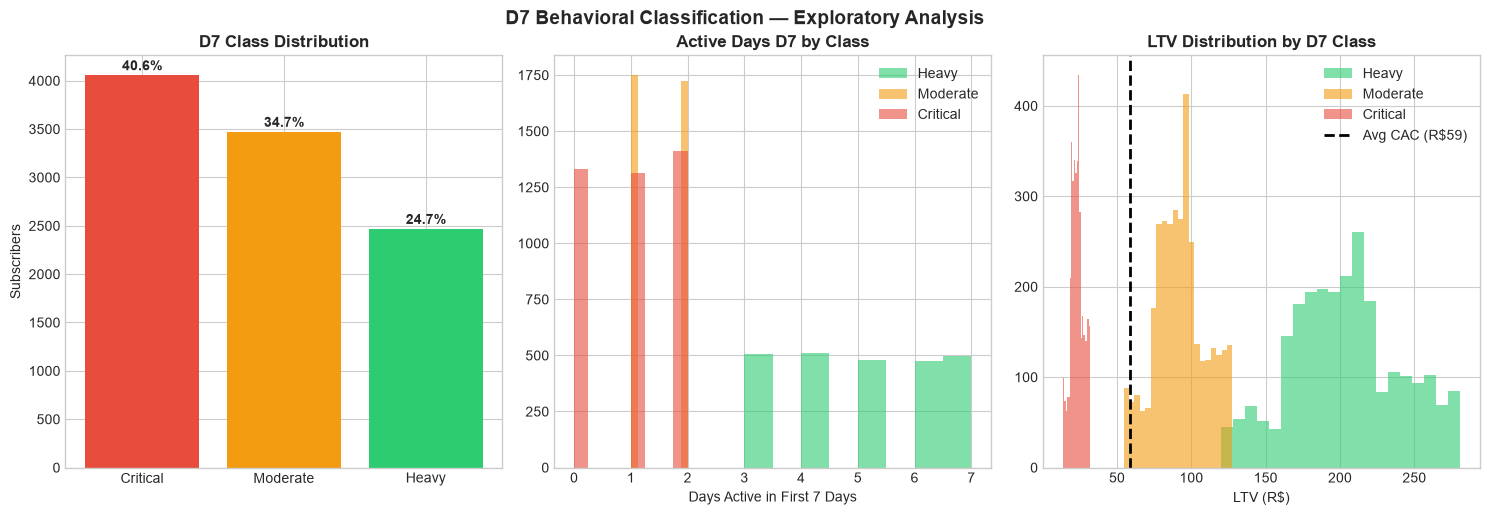

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Class distribution
colors = {'Heavy': '#2ecc71', 'Moderate': '#f39c12', 'Critical': '#e74c3c'}
class_counts = df['d7_class'].value_counts()
axes[0].bar(class_counts.index, class_counts.values, color=[colors[c] for c in class_counts.index])
axes[0].set_title('D7 Class Distribution', fontweight='bold')
axes[0].set_ylabel('Subscribers')
for i, (cls, v) in enumerate(class_counts.items()):
    axes[0].text(i, v + 50, f'{v/len(df):.1%}', ha='center', fontweight='bold')

# Active days by class
for cls, color in colors.items():
    subset = df[df['d7_class'] == cls]['days_active_d7']
    axes[1].hist(subset, alpha=0.6, label=cls, color=color, bins=8)
axes[1].set_title('Active Days D7 by Class', fontweight='bold')
axes[1].set_xlabel('Days Active in First 7 Days')
axes[1].legend()

# LTV distribution by class
for cls, color in colors.items():
    subset = df[df['d7_class'] == cls]['ltv']
    axes[2].hist(subset, alpha=0.6, label=cls, color=color, bins=20)
axes[2].axvline(59, color='black', linestyle='--', linewidth=2, label='Avg CAC (R$59)')
axes[2].set_title('LTV Distribution by D7 Class', fontweight='bold')
axes[2].set_xlabel('LTV (R$)')
axes[2].legend()

plt.tight_layout()
plt.suptitle('D7 Behavioral Classification — Exploratory Analysis', y=1.02, fontsize=14, fontweight='bold')
plt.show()

## 3. Train RandomForest Classifier

In production, the model would be trained on observed D7 behavior and validated against D60/D90 retention outcomes. Here we train on synthetic data to demonstrate the pipeline.

In [5]:
le_plan = LabelEncoder()
le_channel = LabelEncoder()
le_class = LabelEncoder()

df['plan_enc'] = le_plan.fit_transform(df['plan'])
df['channel_enc'] = le_channel.fit_transform(df['acquisition_channel'])
df['class_enc'] = le_class.fit_transform(df['d7_class'])

features = ['days_active_d7', 'plays_d7', 'plan_enc', 'channel_enc']
X = df[features]
y = df['class_enc']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')

Train: 8,000 | Test: 2,000


In [6]:
clf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)

print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=le_class.classes_))

Classification Report:
              precision    recall  f1-score   support

    Critical       1.00      0.87      0.93       812
       Heavy       1.00      1.00      1.00       494
    Moderate       0.86      1.00      0.93       694

    accuracy                           0.95      2000
   macro avg       0.95      0.96      0.95      2000
weighted avg       0.95      0.95      0.95      2000



## 4. AUC Evaluation — Business Threshold: ≥ 0.70

In [7]:
auc_ovr = roc_auc_score(y_test, y_proba, multi_class='ovr', average=None)
print('AUC per class (One-vs-Rest):')
for cls, auc in zip(le_class.classes_, auc_ovr):
    status = '✅ PASS' if auc >= 0.70 else '❌ FAIL'
    print(f'  {cls:10s}: {auc:.4f}  {status}')

macro_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro')
print(f'\nMacro AUC: {macro_auc:.4f}  {"✅ PASS" if macro_auc >= 0.70 else "❌ FAIL"}')
print('\nBusiness threshold: AUC ≥ 0.70 (from experiment design)')

AUC per class (One-vs-Rest):
  Critical  : 0.9863  ✅ PASS
  Heavy     : 1.0000  ✅ PASS
  Moderate  : 0.9855  ✅ PASS

Macro AUC: 0.9906  ✅ PASS

Business threshold: AUC ≥ 0.70 (from experiment design)


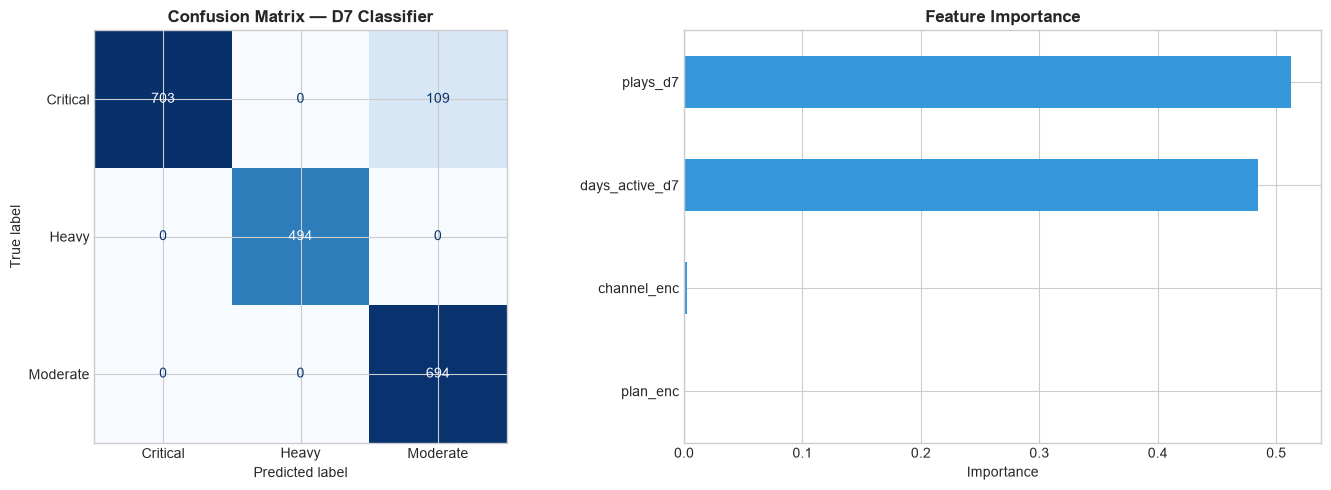

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=le_class.classes_)
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix — D7 Classifier', fontweight='bold')

# Feature importance
importances = pd.Series(clf.feature_importances_, index=features).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='#3498db')
axes[1].set_title('Feature Importance', fontweight='bold')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

## 5. Key Insight

**`plays_d7` and `days_active_d7` are the two dominant predictors** of subscriber class — consistent with the D7 classification thresholds defined in the business case. Plan type adds signal but is secondary.

In a production deployment:
- This model is trained on D7 behavioral data and validated against D60/D90 actual retention (AUC target ≥ 0.70)
- The predicted class is used to generate `pLTV` for each new subscriber
- `pLTV` is uploaded to Meta (AppendValue) and Google (Offline Conversions) within 7 days of purchase